# Experiment 6: K-Means Clustering on Iris Dataset

**Aim:** To perform clustering using the K-Means algorithm on the Iris dataset and visualize the clusters.

**Dataset:** Iris dataset (built into scikit-learn) - 150 records, 4 numeric features. Labels are ignored during clustering.

In [1]:
# Step 1: Import required libraries
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import os
os.makedirs("output", exist_ok=True)   # all plots are saved in this folder

In [2]:
# Step 2: Load the dataset
iris = load_iris()
X = iris.data
features = pd.DataFrame(X, columns=iris.feature_names)
print("Shape:", features.shape)
print(features.head())

Shape: (150, 4)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [3]:
# Step 3: Apply KMeans clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X)
labels = kmeans.labels_

print("Cluster sizes:", pd.Series(labels).value_counts().sort_index().to_dict())
print("Cluster centroids:")
print(pd.DataFrame(kmeans.cluster_centers_, columns=iris.feature_names).round(3))

Cluster sizes: {0: 62, 1: 50, 2: 38}
Cluster centroids:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0              5.902             2.748              4.394             1.434
1              5.006             3.428              1.462             0.246
2              6.850             3.074              5.742             2.071


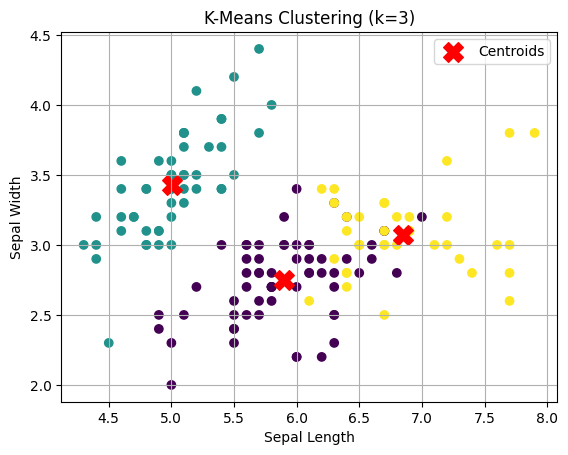

In [4]:
# Step 4: Visualize the clusters using first two features
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            c='red', marker='X', s=200, label='Centroids')
plt.xlabel('Sepal Length')
plt.ylabel('Sepal Width')
plt.title('K-Means Clustering (k=3)')
plt.legend()
plt.grid(True)
plt.savefig("output/Exp6_kmeans_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# Step 5: Print inertia (sum of squared distances)
print("Inertia (Within-Cluster Sum of Squares):", kmeans.inertia_)

Inertia (Within-Cluster Sum of Squares): 78.85144142614601


In [6]:
# Compare clusters with the actual species (labels were not used for training)
print(pd.crosstab(pd.Series(iris.target_names[iris.target], name='Actual species'),
                  pd.Series(labels, name='Cluster')))

Cluster          0   1   2
Actual species            
setosa           0  50   0
versicolor      48   0   2
virginica       14   0  36


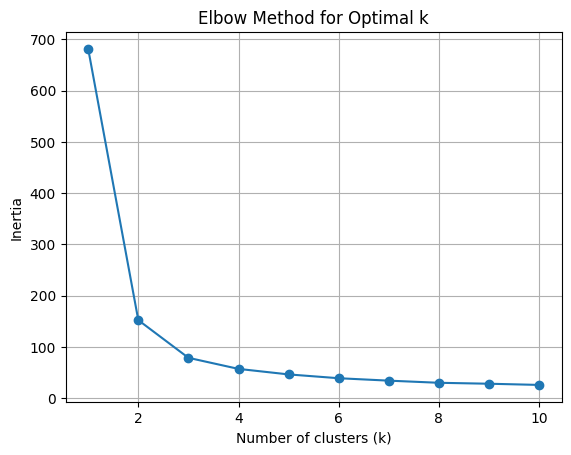

In [7]:
# Elbow method: inertia for different values of k
k_values = range(1, 11)
inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X).inertia_ for k in k_values]

plt.plot(k_values, inertias, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.savefig("output/Exp6_elbow_method.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion
K-Means identified clusters in the Iris dataset without using label information. The cross-tabulation above shows how the clusters compare with the original species.